# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Fauzan Tamma Harish Kunfaza | 5054251035 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset yang digunakan: **Telco Customer Churn** (`WA_Fn-UseC_-Telco-Customer-Churn.csv`), berisi data pelanggan sebuah perusahaan telekomunikasi beserta informasi apakah pelanggan tersebut berhenti berlangganan (*churn*) atau tidak.

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [3]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

sns.set_style("whitegrid")
%matplotlib inline

print("Library berhasil di-import.")

Library berhasil di-import.


In [4]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape dataset:", df.shape)
print()
df.info()
print()
print("Statistik deskriptif (kolom numerik):")
print(df.describe())
print()
print("Jumlah missing value per kolom (deteksi naif):")
print(df.isnull().sum())
print()
blank_totalcharges = (df["TotalCharges"].str.strip() == "").sum()
print(f"Catatan: kolom 'TotalCharges' terbaca sebagai object/string, dan terdapat "
      f"{blank_totalcharges} baris berisi string kosong ('') -> ini adalah missing value "
      f"tersembunyi yang tidak terdeteksi oleh isnull().")

Shape dataset: (7043, 21)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non

C:\Users\fauza\AppData\Local\Temp\ipykernel_50944\2307222277.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Churn", data=df, palette=["#4C72B0", "#DD8452"])


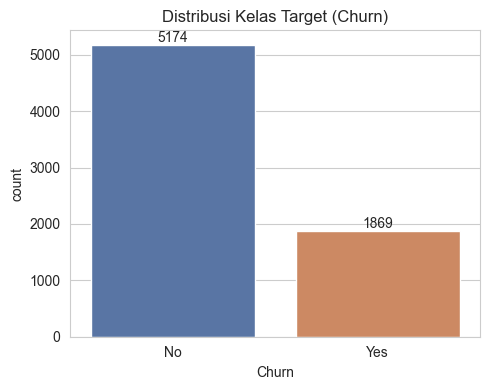

No  (tidak churn): 73.46%
Yes (churn)      : 26.54%
-> Dataset ini IMBALANCED (proporsi kelas 'Yes' jauh lebih kecil, sekitar 1:2.77).


In [5]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(5,4))
ax = sns.countplot(x="Churn", data=df, palette=["#4C72B0", "#DD8452"])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title("Distribusi Kelas Target (Churn)")
plt.tight_layout()
plt.show()

dist = df["Churn"].value_counts(normalize=True) * 100
print(f"No  (tidak churn): {dist['No']:.2f}%")
print(f"Yes (churn)      : {dist['Yes']:.2f}%")
print("-> Dataset ini IMBALANCED (proporsi kelas 'Yes' jauh lebih kecil, sekitar 1:2.77).")

C:\Users\fauza\AppData\Local\Temp\ipykernel_50944\2200664812.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn", y=col, data=df_num_explore, ax=ax, palette=["#4C72B0", "#DD8452"])
C:\Users\fauza\AppData\Local\Temp\ipykernel_50944\2200664812.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn", y=col, data=df_num_explore, ax=ax, palette=["#4C72B0", "#DD8452"])
C:\Users\fauza\AppData\Local\Temp\ipykernel_50944\2200664812.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn", y=col, data=df_num_explore, ax=ax, palett

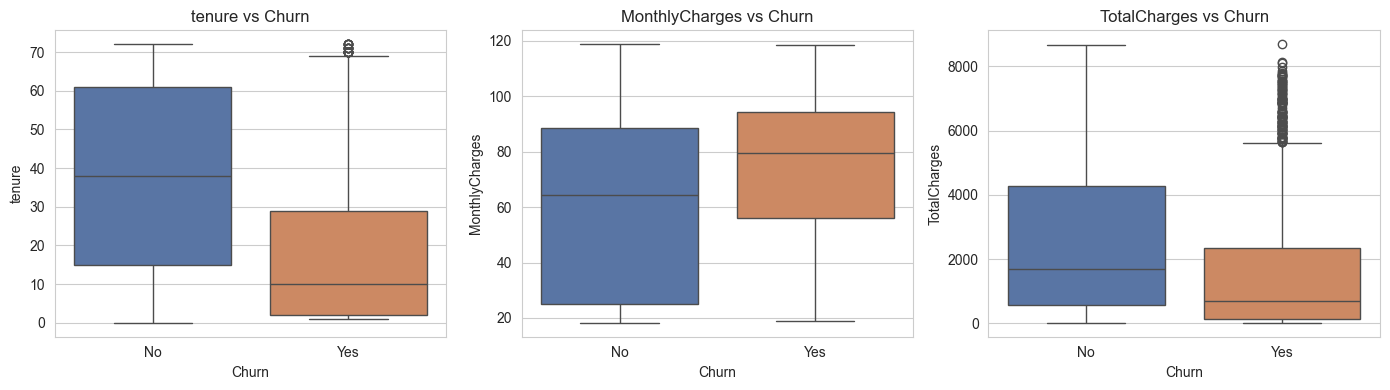

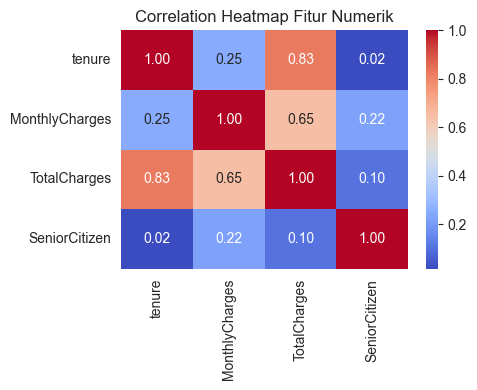

Boxplot menunjukkan pelanggan yang churn cenderung memiliki 'tenure' (lama berlangganan)
yang jauh lebih rendah, dan 'MonthlyCharges' yang sedikit lebih tinggi, dibanding yang tidak churn.
TotalCharges berkorelasi kuat positif dengan tenure (wajar, karena TotalCharges ~ tenure x MonthlyCharges).


In [6]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.
df_num_explore = df.copy()
df_num_explore["TotalCharges"] = pd.to_numeric(df_num_explore["TotalCharges"], errors="coerce")

fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x="Churn", y=col, data=df_num_explore, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_title(f"{col} vs Churn")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5,4))
corr = df_num_explore[["tenure","MonthlyCharges","TotalCharges","SeniorCitizen"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap Fitur Numerik")
plt.tight_layout()
plt.show()

print("Boxplot menunjukkan pelanggan yang churn cenderung memiliki 'tenure' (lama berlangganan)")
print("yang jauh lebih rendah, dan 'MonthlyCharges' yang sedikit lebih tinggi, dibanding yang tidak churn.")
print("TotalCharges berkorelasi kuat positif dengan tenure (wajar, karena TotalCharges ~ tenure x MonthlyCharges).")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

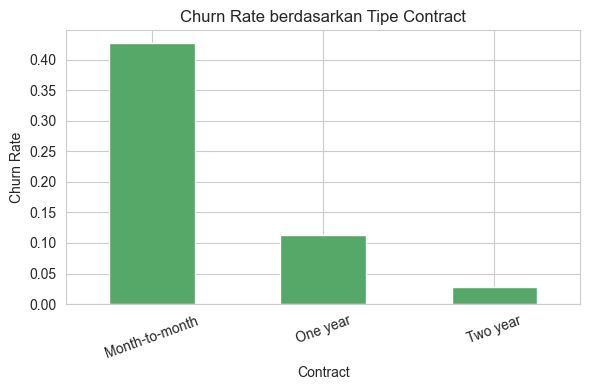

Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Churn, dtype: str

Pelanggan dengan kontrak 'Month-to-month' memiliki churn rate jauh lebih tinggi
(~42.7%) dibanding kontrak 'One year' (~11.3%) maupun 'Two year' (~2.8%).
Tipe kontrak tampak menjadi salah satu fitur paling informatif untuk memprediksi churn.


In [7]:
# EDA tambahan: churn rate berdasarkan tipe kontrak (Contract)
churn_by_contract = df.groupby("Contract")["Churn"].apply(lambda s: (s=="Yes").mean())

plt.figure(figsize=(6,4))
churn_by_contract.plot(kind="bar", color="#55A868")
plt.ylabel("Churn Rate")
plt.title("Churn Rate berdasarkan Tipe Contract")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(churn_by_contract.apply(lambda x: f"{x*100:.2f}%"))
print()
print("Pelanggan dengan kontrak 'Month-to-month' memiliki churn rate jauh lebih tinggi")
print("(~42.7%) dibanding kontrak 'One year' (~11.3%) maupun 'Two year' (~2.8%).")
print("Tipe kontrak tampak menjadi salah satu fitur paling informatif untuk memprediksi churn.")

# 2. Preprocessing

In [8]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
print("Jumlah NaN pada TotalCharges setelah konversi ke numerik:", data["TotalCharges"].isna().sum())
print(data.loc[data["TotalCharges"].isna(), ["tenure","MonthlyCharges","TotalCharges"]])

data["TotalCharges"] = data["TotalCharges"].fillna(0)
print()
print("Seluruh baris yang kosong memiliki tenure = 0 (pelanggan baru), sehingga secara logis")
print("TotalCharges memang belum ada tagihan -> diisi dengan 0 (bukan mean/median, agar sesuai konteks domain).")
print("Missing value tersisa setelah penanganan:", data.isnull().sum().sum())

Jumlah NaN pada TotalCharges setelah konversi ke numerik: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN

Seluruh baris yang kosong memiliki tenure = 0 (pelanggan baru), sehingga secara logis
TotalCharges memang belum ada tagihan -> diisi dengan 0 (bukan mean/median, agar sesuai konteks domain).
Missing value tersisa setelah penanganan: 0


In [9]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
data = data.drop(columns=["customerID"])  # ID unik -> bukan fitur prediktif, buang agar tidak leakage

binary_map_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
for col in binary_map_cols:
    data[col] = data[col].map({"Yes": 1, "No": 0})
data["gender"] = data["gender"].map({"Male": 1, "Female": 0})

multi_cat_cols = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                   "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                   "Contract", "PaymentMethod"]
data = pd.get_dummies(data, columns=multi_cat_cols, drop_first=True)

print("customerID dibuang (ID unik, tidak berguna sebagai fitur dan berisiko leakage/overfitting).")
print("Kolom biner (Yes/No) di-encode manual menjadi 1/0: gender, Partner, Dependents, PhoneService, PaperlessBilling, Churn.")
print("Kolom kategorikal multi-kelas di-One-Hot Encoding (pd.get_dummies, drop_first=True):")
print(" ", multi_cat_cols)
print()
print("Shape data setelah encoding:", data.shape)
print(data.dtypes)

customerID dibuang (ID unik, tidak berguna sebagai fitur dan berisiko leakage/overfitting).
Kolom biner (Yes/No) di-encode manual menjadi 1/0: gender, Partner, Dependents, PhoneService, PaperlessBilling, Churn.
Kolom kategorikal multi-kelas di-One-Hot Encoding (pd.get_dummies, drop_first=True):
  ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

Shape data setelah encoding: (7043, 31)
gender                                     int64
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
PhoneService                               int64
PaperlessBilling                           int64
MonthlyCharges                           float64
TotalCharges                             float64
Churn                                      int64
Mu

In [10]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = data.drop(columns=["Churn"])
y = data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("X shape:", X.shape, " y shape:", y.shape)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Proporsi churn train:", y_train.mean().round(4), " test:", y_test.mean().round(4))

X shape: (7043, 30)  y shape: (7043,)
X_train: (5634, 30)  X_test: (1409, 30)
Proporsi churn train: 0.2654  test: 0.2654


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [11]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Fitur numerik (tenure, MonthlyCharges, TotalCharges) di-scaling dengan StandardScaler.")
print("Fitur biner/one-hot (0/1) tidak perlu di-scaling ulang karena sudah dalam rentang seragam.")
print()
print(X_train_scaled[numeric_cols].describe().loc[["mean","std"]])

Fitur numerik (tenure, MonthlyCharges, TotalCharges) di-scaling dengan StandardScaler.
Fitur biner/one-hot (0/1) tidak perlu di-scaling ulang karena sudah dalam rentang seragam.

            tenure  MonthlyCharges  TotalCharges
mean -1.008935e-17   -2.402527e-16  2.522338e-17
std   1.000089e+00    1.000089e+00  1.000089e+00


# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [12]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).
baseline = MLPClassifier(hidden_layer_sizes=(10,), activation="relu",
                          max_iter=500, random_state=42)
baseline.fit(X_train_scaled, y_train)

print("Model baseline selesai dilatih.")
print("hidden_layer_sizes=(10,), activation='relu', max_iter=500")
print("Jumlah iterasi aktual sampai konvergen:", baseline.n_iter_)

Model baseline selesai dilatih.
hidden_layer_sizes=(10,), activation='relu', max_iter=500
Jumlah iterasi aktual sampai konvergen: 271


In [13]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_baseline = baseline.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred_baseline)
print("Akurasi baseline pada test set:", round(acc, 4))

Akurasi baseline pada test set: 0.7906


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [14]:
# Latih beberapa model MLPClassifier dengan arsitektur yang sama, tetapi activation berbeda:
# 'relu', 'tanh', dan 'logistic'.
# Gunakan hyperparameter lain yang sama (hidden_layer_sizes, max_iter, random_state) agar perbandingan adil.
activations = ["relu", "tanh", "logistic"]
act_results = {}
act_models = {}

for act in activations:
    m = MLPClassifier(hidden_layer_sizes=(10,), activation=act,
                       max_iter=500, random_state=42)
    m.fit(X_train_scaled, y_train)
    pred = m.predict(X_test_scaled)
    act_results[act] = accuracy_score(y_test, pred)
    act_models[act] = m
    print(f"activation={act:10s} -> test accuracy = {act_results[act]:.4f}  (n_iter={m.n_iter_})")

activation=relu       -> test accuracy = 0.7906  (n_iter=271)
activation=tanh       -> test accuracy = 0.7977  (n_iter=273)
activation=logistic   -> test accuracy = 0.7977  (n_iter=161)


In [15]:
# Hitung dan bandingkan akurasi test set dari ketiga fungsi aktivasi tersebut.
# Sajikan dalam tabel perbandingan.
tabel_aktivasi = pd.DataFrame({
    "Activation": list(act_results.keys()),
    "Test Accuracy": list(act_results.values())
}).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
print(tabel_aktivasi.to_string(index=False))

best_activation = max(act_results, key=act_results.get)
best_act_model = act_models[best_activation]
print()
print(f"Fungsi aktivasi terbaik (test accuracy tertinggi): '{best_activation}'")

Activation  Test Accuracy
      tanh       0.797729
  logistic       0.797729
      relu       0.790632

Fungsi aktivasi terbaik (test accuracy tertinggi): 'tanh'


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [16]:
# Latih beberapa model MLPClassifier dengan variasi hidden_layer_sizes,
# misalnya (2,), (5,), (10,), (50,), (100, 50).
# Gunakan activation terbaik dari hasil eksperimen 3.2, dan hyperparameter lain yang sama.
architectures = [(2,), (5,), (10,), (50,), (100, 50)]
arch_results = []
arch_models = {}

for arch in architectures:
    m = MLPClassifier(hidden_layer_sizes=arch, activation=best_activation,
                       max_iter=500, random_state=42)
    m.fit(X_train_scaled, y_train)
    train_acc = accuracy_score(y_train, m.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, m.predict(X_test_scaled))
    arch_results.append({"arch": str(arch), "train_acc": train_acc, "test_acc": test_acc})
    arch_models[str(arch)] = m
    print(f"hidden_layer_sizes={str(arch):12s} -> train acc={train_acc:.4f}  test acc={test_acc:.4f}")

hidden_layer_sizes=(2,)         -> train acc=0.8046  test acc=0.7956
hidden_layer_sizes=(5,)         -> train acc=0.8113  test acc=0.7984
hidden_layer_sizes=(10,)        -> train acc=0.8181  test acc=0.7977


c:\Users\fauza\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


hidden_layer_sizes=(50,)        -> train acc=0.8482  test acc=0.7793
hidden_layer_sizes=(100, 50)    -> train acc=0.9650  test acc=0.7509


c:\Users\fauza\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [17]:
# Hitung akurasi pada train set dan test set untuk setiap arsitektur yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
arch_df = pd.DataFrame(arch_results)
arch_df["gap (train-test)"] = arch_df["train_acc"] - arch_df["test_acc"]
print(arch_df.to_string(index=False))

     arch  train_acc  test_acc  gap (train-test)
     (2,)   0.804579  0.795600          0.008980
     (5,)   0.811324  0.798439          0.012885
    (10,)   0.818069  0.797729          0.020340
    (50,)   0.848243  0.779276          0.068967
(100, 50)   0.965034  0.750887          0.214147


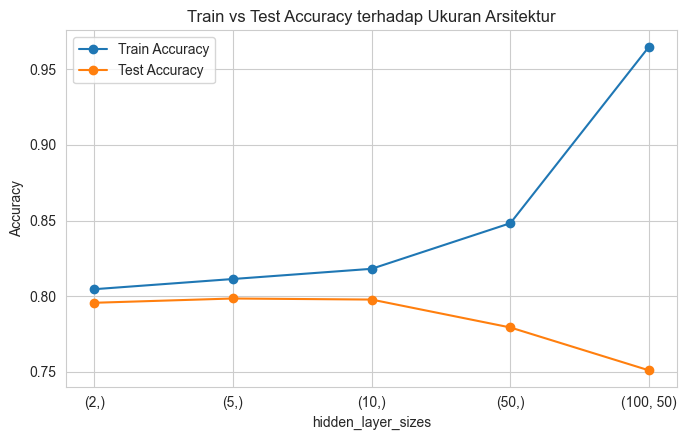

Test accuracy tertinggi dicapai pada hidden_layer_sizes=(5,) (test acc=0.7984).
Mulai hidden_layer_sizes=(50,) gap train-test melebar signifikan -> indikasi overfitting.
Pada (100, 50), train acc mencapai ~0.965 namun test acc justru turun ke ~0.751 -> overfitting parah.


In [18]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
labels = [r["arch"] for r in arch_results]
train_accs = [r["train_acc"] for r in arch_results]
test_accs = [r["test_acc"] for r in arch_results]

plt.figure(figsize=(7,4.5))
plt.plot(labels, train_accs, marker="o", label="Train Accuracy")
plt.plot(labels, test_accs, marker="o", label="Test Accuracy")
plt.xlabel("hidden_layer_sizes")
plt.ylabel("Accuracy")
plt.title("Train vs Test Accuracy terhadap Ukuran Arsitektur")
plt.legend()
plt.tight_layout()
plt.show()

best_arch_row = max(arch_results, key=lambda r: r["test_acc"])
best_arch_model = arch_models[best_arch_row["arch"]]
print(f"Test accuracy tertinggi dicapai pada hidden_layer_sizes={best_arch_row['arch']} "
      f"(test acc={best_arch_row['test_acc']:.4f}).")
print("Mulai hidden_layer_sizes=(50,) gap train-test melebar signifikan -> indikasi overfitting.")
print("Pada (100, 50), train acc mencapai ~0.965 namun test acc justru turun ke ~0.751 -> overfitting parah.")

# 4. Evaluasi Model

In [19]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
def metrics_row(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
    }

best_32_pred = best_act_model.predict(X_test_scaled)
best_33_pred = best_arch_model.predict(X_test_scaled)

eval_table = pd.DataFrame([
    metrics_row(f"Terbaik 3.2 (activation={best_activation})", y_test, best_32_pred),
    metrics_row(f"Terbaik 3.3 (hidden_layer_sizes={best_arch_row['arch']})", y_test, best_33_pred),
])
print(eval_table.round(4).to_string(index=False))

                                Model  Accuracy  Precision  Recall  F1-Score
        Terbaik 3.2 (activation=tanh)    0.7977     0.6478  0.5214    0.5778
Terbaik 3.3 (hidden_layer_sizes=(5,))    0.7984     0.6424  0.5428    0.5884


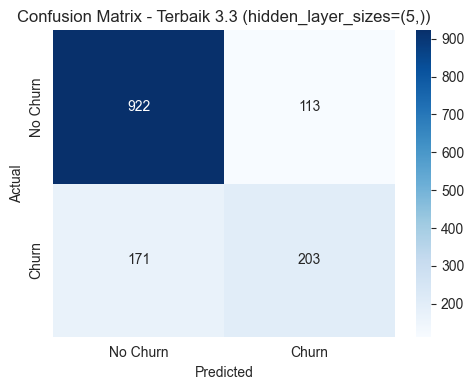

Model dengan performa terbaik secara keseluruhan: Terbaik 3.3 (hidden_layer_sizes=(5,))

Classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.87      1035
       Churn       0.64      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [20]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.
if eval_table.iloc[0]["Accuracy"] >= eval_table.iloc[1]["Accuracy"]:
    overall_best_model, overall_best_name, overall_best_pred = best_act_model, eval_table.iloc[0]["Model"], best_32_pred
else:
    overall_best_model, overall_best_name, overall_best_pred = best_arch_model, eval_table.iloc[1]["Model"], best_33_pred

cm = confusion_matrix(y_test, overall_best_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn","Churn"], yticklabels=["No Churn","Churn"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {overall_best_name}")
plt.tight_layout()
plt.show()

print(f"Model dengan performa terbaik secara keseluruhan: {overall_best_name}")
print()
print("Classification report:")
print(classification_report(y_test, overall_best_pred, target_names=["No Churn","Churn"]))

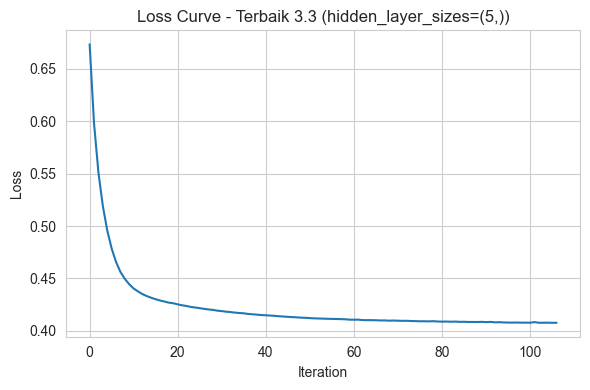

Jumlah iterasi sampai training berhenti: 107 / max_iter=500
Loss akhir: 0.4076
Training berhenti sebelum mencapai max_iter -> optimizer konvergen (perubahan loss < tol),
kurva sudah landai/flat di ujung, menandakan model sudah cukup konvergen.


In [21]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.
plt.figure(figsize=(6,4))
plt.plot(overall_best_model.loss_curve_)
plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.title(f"Loss Curve - {overall_best_name}")
plt.tight_layout()
plt.show()

print("Jumlah iterasi sampai training berhenti:", overall_best_model.n_iter_, "/ max_iter=500")
print("Loss akhir:", round(overall_best_model.loss_curve_[-1], 4))
print("Training berhenti sebelum mencapai max_iter -> optimizer konvergen (perubahan loss < tol),")
print("kurva sudah landai/flat di ujung, menandakan model sudah cukup konvergen.")

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

---

**1. Perbandingan fungsi aktivasi (ReLU vs Tanh vs Logistic)**

Dari eksperimen 3.2, ketiga fungsi aktivasi menghasilkan akurasi test yang sangat berdekatan: ReLU 79.06%, Tanh 79.77%, dan Logistic 79.77%. Selisihnya kurang dari 1 poin persentase, sehingga secara praktis perbedaannya **tidak signifikan** untuk kasus ini. Ada dua alasan utama yang mendasari:

- Arsitektur yang digunakan hanya **satu hidden layer dengan 10 neuron** (dangkal/shallow). Masalah seperti *vanishing gradient*, yang biasanya menjadi alasan ReLU unggul dibanding Tanh/Logistic, baru terasa signifikan pada jaringan yang **dalam** (banyak hidden layer). Pada jaringan dangkal seperti ini, gradien masih bisa mengalir dengan baik meski memakai fungsi aktivasi yang saturating (Tanh/Logistic).
- Dataset churn ini bersifat tabular dengan pola pemisahan kelas yang relatif tidak terlalu kompleks (banyak fitur biner/kategorikal hasil one-hot encoding), sehingga kemampuan non-linearitas tambahan dari satu jenis aktivasi dibanding yang lain tidak banyak berpengaruh terhadap kemampuan model memisahkan kelas.

**2. Pengaruh ukuran arsitektur terhadap overfitting**

Hasil eksperimen 3.3 (menggunakan activation='tanh', hasil terbaik dari 3.2):

| hidden_layer_sizes | Train Acc | Test Acc | Gap |
|---|---|---|---|
| (2,) | 0.8046 | 0.7956 | 0.0090 |
| (5,) | 0.8113 | 0.7984 | 0.0129 |
| (10,) | 0.8181 | 0.7977 | 0.0204 |
| (50,) | 0.8482 | 0.7793 | 0.0689 |
| (100, 50) | 0.9650 | 0.7509 | 0.2142 |

Pada arsitektur kecil, (2,) sampai (10,), train dan test accuracy masih berdekatan (gap < 3 poin persen) dan test accuracy relatif stabil di sekitar 79.6%-79.8%. **Gejala overfitting mulai terlihat jelas mulai dari hidden_layer_sizes=(50,)**: train accuracy terus naik (84.8%) tetapi test accuracy justru **turun** (77.9%), sehingga gap melebar menjadi hampir 7 poin persen. Pada arsitektur (100, 50), overfitting menjadi **parah**: train accuracy melonjak ke 96.5% (model nyaris menghafal data training) sementara test accuracy justru anjlok ke 75.1% — gap mencapai lebih dari 21 poin persen. Ini adalah ciri klasik overfitting: kapasitas model yang terlalu besar dibanding kompleksitas pola sebenarnya di data membuat model mulai "menghafal" noise/detail spesifik data training, alih-alih mempelajari pola umum yang bisa digeneralisasi ke data baru.

**3. Konvergensi loss curve**

Model terbaik (hidden_layer_sizes=(5,), activation='tanh') berhenti training pada iterasi ke-107 dari maksimum 500 iterasi, dengan loss akhir sekitar 0.41. Kurva loss menurun tajam pada ~10 iterasi pertama (dari ±0.67 ke ±0.43), lalu melandai secara bertahap hingga stabil di sekitar 0.41. Karena training berhenti **sebelum** mencapai max_iter (solver `adam` di scikit-learn berhenti otomatis ketika penurunan loss antar-iterasi sudah lebih kecil dari `tol`), dan bentuk kurva pada bagian akhir sudah landai/flat, dapat disimpulkan **model sudah cukup konvergen**.

Jika seandainya loss curve masih menurun tajam saat max_iter tercapai (belum konvergen), langkah yang akan diambil antara lain:
- Menaikkan `max_iter` agar model punya kesempatan lebih untuk mencapai konvergensi.
- Menurunkan `learning_rate_init` jika loss terlihat "berosilasi" (bukan menurun mulus), atau menaikkannya jika penurunannya terlalu lambat.
- Mengaktifkan `early_stopping=True` dengan `validation_fraction` agar training dihentikan berdasarkan performa di validation set, bukan hanya loss training.
- Mencoba solver lain (misalnya `sgd` dengan momentum) yang mungkin lebih cocok untuk skala data ini.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba solver lain seperti 'sgd', menambahkan regularisasi alpha, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

**Kesimpulan**

Model ANN (MLPClassifier) berhasil dibangun untuk memprediksi churn pelanggan telekomunikasi dengan akurasi test terbaik sekitar **79.8%** (hidden_layer_sizes=(5,), activation='tanh'). Namun demikian, precision (~64%) dan terutama recall (~54%) untuk kelas 'Churn' masih tergolong sedang — artinya model masih cukup sering gagal mendeteksi pelanggan yang benar-benar akan churn (false negative), yang konsisten dengan sifat dataset yang imbalanced (~73% No vs ~27% Yes). Pemilihan fungsi aktivasi (ReLU/Tanh/Logistic) tidak memberikan perbedaan performa yang signifikan pada arsitektur dangkal yang digunakan. Sebaliknya, ukuran arsitektur berpengaruh besar: arsitektur kecil hingga sedang ((2,) sampai (10,) neuron) sudah cukup untuk menangkap pola pada data ini, sementara arsitektur yang lebih besar ((50,) dan (100, 50)) justru menyebabkan overfitting — akurasi training meningkat tajam tetapi akurasi test menurun.

**Saran untuk eksperimen selanjutnya**

- **Tangani class imbalance** secara eksplisit, misalnya dengan teknik oversampling (SMOTE) pada training set, atau menyesuaikan threshold keputusan, agar recall untuk kelas 'Churn' (kelas minoritas yang justru paling penting secara bisnis) dapat ditingkatkan.
- **Hyperparameter tuning** menggunakan `GridSearchCV` atau `RandomizedSearchCV`, mencakup `alpha` (regularisasi L2), `hidden_layer_sizes`, `learning_rate_init`, dan `activation` secara bersamaan, dievaluasi dengan cross-validation agar hasil lebih robust dibanding satu kali split train-test.
- **Tambahkan regularisasi** (`alpha` lebih besar) atau gunakan `early_stopping=True` pada arsitektur besar seperti (50,) dan (100, 50) untuk melihat apakah overfitting dapat dikurangi tanpa harus memperkecil arsitektur.
- **Bandingkan dengan model lain** seperti Logistic Regression, Random Forest, atau Gradient Boosting (misalnya XGBoost) sebagai pembanding, karena untuk data tabular seperti ini model berbasis pohon seringkali kompetitif atau bahkan lebih baik dibanding ANN.
- **Feature engineering tambahan**, misalnya membuat fitur rasio (TotalCharges/tenure) atau melakukan feature selection untuk mengurangi dimensi hasil one-hot encoding yang cukup banyak.